# Notebook 03 — Classificador SVM único: **Norm_e_Sr** — PTB-XL

**Objetivo:** treinar **um único classificador binário SVM**, com rótulo positivo se o ECG possuir o código SCP `NORM` **ou** `SR` (`NORM ∪ SR`). Cada ECG conta apenas uma vez, mesmo quando possui ambos os códigos.

**Saída final exclusiva:** `modelos_normais/Norm_e_Sr.joblib`.

> **Interpretação importante:** `NORM` é um código diagnóstico e `SR` representa ritmo sinusal. A união corresponde à **presença de ao menos um desses códigos**, não a uma garantia clínica de normalidade. Um ECG com `SR` e alterações pode ser positivo para este alvo. Portanto, a interface deve usar a descrição **“Rótulo NORM ou SR”** / “Padrões NORM/SR”, e não “probabilidade de coração saudável”.

Mantém o fluxo dos notebooks oficiais: análise de códigos, 12 derivações, idade/sexo, folds PTB-XL, SVM RBF, Platt no fold 9, avaliação no fold 10, gráficos, métricas, CSVs e `.joblib`. O treinamento **não acontece ao abrir o arquivo**: execute as células com os sinais WFDB presentes.

## 1. Dependências e execução

Utilize Python 3.10–3.12, de preferência em um ambiente virtual. No terminal: `python -m pip install numpy pandas scipy scikit-learn==1.4.2 wfdb joblib matplotlib altair nbformat ipykernel`.

Copie o notebook para uma pasta de trabalho e ajuste `BASE` na célula seguinte. Ele cria `modelos_normais/` dentro de `BASE`, preservando os arquivos originais.

In [1]:
from pathlib import Path
import ast, json, warnings, platform, hashlib
import numpy as np
import pandas as pd
import scipy, sklearn, wfdb, joblib
from scipy import signal
from scipy.integrate import trapezoid
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score, roc_auc_score, average_precision_score,
    brier_score_loss, roc_curve, precision_recall_curve)
from sklearn.calibration import calibration_curve
from IPython.display import display

SEED = 42
BASE = Path(r"C:\Users\Matheus\Documents\PTB-XL")
# Para explorar os CSVs anexados antes de treinar, use BASE = Path('/mnt/data')
METADATA_CSV = BASE / 'ptbxl_database.csv'
SCP_CSV = BASE / 'scp_statements.csv'
DESTINO = BASE / 'modelos_normais'
CACHE = DESTINO / 'cache' / 'features_norm_e_sr_v1.pkl'
DESTINO.mkdir(parents=True, exist_ok=True)
CACHE.parent.mkdir(parents=True, exist_ok=True)
for sub in ('relatorios', 'graficos', 'previsoes'):
    (DESTINO / sub).mkdir(exist_ok=True)
MAX_REGISTROS = 0  # 0 = todos; se >0, amostra exploratória por fold
MAX_TREINO_POR_CLASSE = 2500  # mesmo controle de custo do notebook 01; 0 = sem limite
C_CANDIDATOS = [0.3, 1.0, 3.0]
LEADS = ['I','II','III','aVR','aVL','aVF','V1','V2','V3','V4','V5','V6']
FOLDS_TREINO = list(range(1,9))
FOLD_CALIBRACAO = 9
FOLD_TESTE = 10
assert METADATA_CSV.is_file() and SCP_CSV.is_file(), 'Ajuste BASE para a pasta dos CSVs.'
print('BASE:',BASE,'\nDESTINO:',DESTINO,'\nscikit-learn:',sklearn.__version__)

BASE: C:\Users\Matheus\Documents\PTB-XL 
DESTINO: C:\Users\Matheus\Documents\PTB-XL\modelos_normais 
scikit-learn: 1.4.2


## 2. Auditoria dos códigos SCP e definição do **único alvo**

A variável positiva `Norm_e_Sr=1` ocorre quando `NORM in scp_codes OR SR in scp_codes`. Registros com os dois códigos não são duplicados. Os outros registros elegíveis serão negativos. Mantemos o filtro de conflitos explícitos `NORM` + categorias diagnósticas anormais conforme o notebook de referência; este filtro é documentado e contabilizado, mas **não remove automaticamente um ECG só porque possui `SR` e outro código**.

In [2]:
metadata_all = pd.read_csv(METADATA_CSV)
scp = pd.read_csv(SCP_CSV, index_col=0)
scp.index = scp.index.astype(str)
for c in ('NORM','SR'):
    assert c in scp.index, f'Código SCP ausente: {c}'
print('Definições SCP:')
display(scp.loc[['NORM','SR'], ['description','diagnostic','rhythm','diagnostic_class']])

def parse_codes(value):
    try:
        d = ast.literal_eval(value) if isinstance(value,str) else value
        return set(map(str,d.keys())) if isinstance(d,dict) else set()
    except (ValueError,SyntaxError,TypeError):
        return set()

metadata_all['code_set'] = metadata_all['scp_codes'].map(parse_codes)
metadata_all['NORM'] = metadata_all['code_set'].map(lambda s: int('NORM' in s))
metadata_all['SR'] = metadata_all['code_set'].map(lambda s: int('SR' in s))
metadata_all['Norm_e_Sr'] = ((metadata_all['NORM'] == 1) | (metadata_all['SR'] == 1)).astype(int)

def diag_abnormal(code):
    if code not in scp.index: return False
    classe = scp.loc[code,'diagnostic_class']
    return pd.notna(classe) and str(classe).strip() in {'MI','STTC','CD','HYP'}

metadata_all['conflito_norm_anormal'] = metadata_all['code_set'].map(
    lambda codes: 'NORM' in codes and any(diag_abnormal(c) for c in codes))
metadata_all['sem_codigo'] = ~metadata_all['code_set'].map(bool)
metadata = metadata_all.loc[
    ~metadata_all['conflito_norm_anormal'] & ~metadata_all['sem_codigo']
].copy()

if MAX_REGISTROS:
    metadata = pd.concat([
        part.sample(n=min(len(part),max(1,MAX_REGISTROS//10)),random_state=SEED)
        for _,part in metadata.groupby('strat_fold')
    ]).sort_values('ecg_id').reset_index(drop=True)

print('Registros totais:',len(metadata_all))
print('Excluídos por NORM e anormal:',int(metadata_all.conflito_norm_anormal.sum()))
print('Sem SCP:',int(metadata_all.sem_codigo.sum()))
print('Elegíveis:',len(metadata))
audit_labels = pd.DataFrame([{
    'alvo': label,'positivos':int(metadata[label].sum()),
    'negativos':int((metadata[label]==0).sum()),
    'percentual_positivo':round(metadata[label].mean()*100,2)
} for label in ('Norm_e_Sr',)])
display(audit_labels)
audit_labels.to_csv(DESTINO/'relatorios'/'auditoria_alvos.csv',index=False,encoding='utf-8-sig')
assert metadata.ecg_id.is_unique
assert metadata['Norm_e_Sr'].eq(metadata['NORM'] | metadata['SR']).all()
assert metadata.strat_fold.between(1,10).all()
patient_folds=metadata.dropna(subset=['patient_id']).groupby('patient_id').strat_fold.nunique()
assert not (patient_folds>1).any(), 'Vazamento: paciente em folds diferentes!'
print('Folds por registro:');display(metadata.strat_fold.value_counts().sort_index().rename('n').to_frame())

Definições SCP:


,description,diagnostic,rhythm,diagnostic_class
NORM,normal ECG,1.0,NaN,NORM
SR,sinus rhythm,NaN,1.0,NaN


Registros totais: 21799
Excluídos por NORM e anormal: 445
Sem SCP: 0
Elegíveis: 21354


,alvo,positivos,negativos,percentual_positivo
0,Norm_e_Sr,17613,3741,82.48


Folds por registro:


,n
strat_fold,
1,2133
2,2139
3,2142
4,2132
5,2128
6,2133
7,2128
8,2130
9,2142


## 3. Interseção e união: evitando contagem dupla

O gráfico abaixo apenas explica como `NORM` e `SR` contribuem para o mesmo alvo. A soma das quantidades brutas supercontaria ECGs com ambos os códigos. Calculamos **união**, não soma aritmética.

SR,False,True
NORM,,
False,3741,8544
True,1310,8204


,grupo,n,percentual_total
0,Apenas NORM,1310,6.009450
1,Apenas SR,8544,39.194458
2,NORM e SR,8204,37.634754
3,Nenhum,3741,17.161338


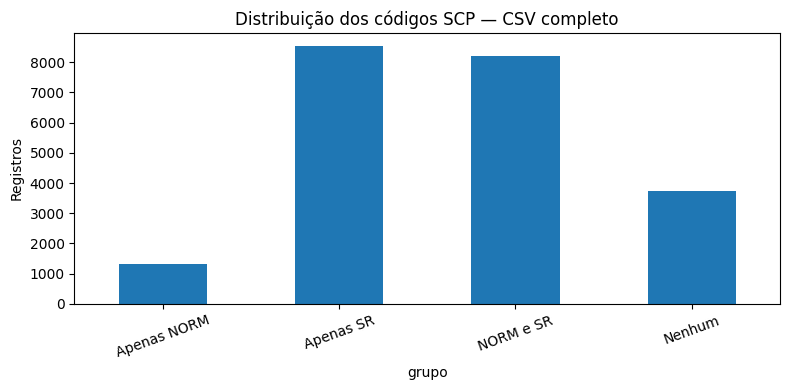

Total da união NORM ∪ SR: 18058 de 21799 ECGs no CSV bruto
Total elegível (após filtros): 17613 de 21354


In [3]:
a=metadata_all.NORM.astype(bool); b=metadata_all.SR.astype(bool)
contingencia=pd.crosstab(a,b,rownames=['NORM'],colnames=['SR'])
display(contingencia)
contagens=pd.DataFrame([{'grupo':'Apenas NORM','n':int((a&~b).sum())},
 {'grupo':'Apenas SR','n':int((~a&b).sum())},
 {'grupo':'NORM e SR','n':int((a&b).sum())},
 {'grupo':'Nenhum','n':int((~a&~b).sum())}])
contagens['percentual_total']=100*contagens.n/len(metadata_all)
display(contagens)
ax=contagens.plot.bar(x='grupo',y='n',legend=False,figsize=(8,4),rot=20)
ax.set_ylabel('Registros');ax.set_title('Distribuição dos códigos SCP — CSV completo')
plt.tight_layout();plt.show()
print('Total da união NORM ∪ SR:',int((a|b).sum()),'de',len(metadata_all),'ECGs no CSV bruto')
print('Total elegível (após filtros):',int(metadata['Norm_e_Sr'].sum()),'de',len(metadata))


## 4. Extração de características dos sinais WFDB

**Mesma família de características do Notebook 01:** 12 derivações × 9 variáveis (incluindo `valid`), oito características de RR/FC e 12 descritores demográficos/contextuais, totalizando 128. As fórmulas de filtragem e detecção de picos foram preservadas a partir do código de referência. Não se utiliza o rótulo como característica.

In [4]:
def clean_signal(x, fs):
    x = np.asarray(x, dtype=float)

    if len(x) < 3 * fs:
        return None

    good = np.isfinite(x)

    if good.mean() < 0.99:
        return None

    x = np.where(good, x, np.nanmedian(x[good]))

    hi = min(40.0, fs * 0.4)

    if hi <= 0.5:
        return None

    sos = signal.butter(
        3, [0.5, hi],
        btype="bandpass",
        fs=fs,
        output="sos"
    )

    return signal.sosfiltfilt(sos, x)


METRICAS_LEAD = [
    "std", "rms", "ptp", "mad",
    "deriv_mad", "energy_1_5",
    "energy_5_15", "energy_15_35"
]

def lead_features(raw, fs, lead):
    x = clean_signal(raw, fs)

    if x is None:
        out = {
            f"{lead}_{k}": np.nan
            for k in METRICAS_LEAD
        }
        out[f"{lead}_valid"] = 0
        return out

    out = {
        f"{lead}_valid": 1,
        f"{lead}_std": float(np.std(x)),
        f"{lead}_rms": float(np.sqrt(np.mean(x*x))),
        f"{lead}_ptp": float(np.ptp(x)),
        f"{lead}_mad": float(
            np.median(np.abs(x - np.median(x)))
        ),
        f"{lead}_deriv_mad": float(
            np.median(np.abs(np.diff(x)))
        )
    }

    freq, psd = signal.welch(
        x, fs=fs,
        nperseg=min(len(x), int(2*fs))
    )

    for a, b, name in [
        (1, 5, "energy_1_5"),
        (5, 15, "energy_5_15"),
        (15, 35, "energy_15_35")
    ]:
        mask = (freq >= a) & (freq < b)

        out[f"{lead}_{name}"] = (
            float(trapezoid(psd[mask], x=freq[mask]))
            if mask.sum() > 1
            else np.nan
        )

    return out


def rhythm_summary(x, fs):
    names = [
        "n_peaks", "hr_bpm", "rr_mean_ms",
        "rr_sd_ms", "rr_cv", "rmssd_ms",
        "rr_p10_ms", "rr_p90_ms"
    ]

    out = {k: np.nan for k in names}

    x = clean_signal(x, fs)

    if x is None:
        return out

    sos = signal.butter(
        2, [5, min(20, fs * 0.4)],
        btype="bandpass",
        fs=fs,
        output="sos"
    )

    y = signal.sosfiltfilt(sos, x)

    grad = np.gradient(y)

    width = max(3, int(0.08 * fs))

    energy = np.convolve(
        grad**2,
        np.ones(width) / width,
        mode="same"
    )

    peaks, _ = signal.find_peaks(
        energy,
        distance=max(1, int(0.28 * fs)),
        prominence=max(
            np.percentile(energy, 85) * 0.3,
            1e-12
        )
    )

    refined = []

    for p in peaks:
        left = max(0, p - int(0.075*fs))
        right = min(len(y), p + int(0.075*fs) + 1)

        if right > left:
            refined.append(
                left + int(np.argmax(np.abs(y[left:right])))
            )

    refined = np.unique(refined)

    if len(refined) > 1:
        keep = np.r_[
            True,
            np.diff(refined) > int(0.24 * fs)
        ]
        refined = refined[keep]

    rr = np.diff(refined) / fs

    rr = rr[(rr >= 0.28) & (rr <= 2.5)]

    if len(rr) < 4:
        return out

    out.update({
        "n_peaks": float(len(refined)),
        "hr_bpm": float(60 / np.mean(rr)),
        "rr_mean_ms": float(1000 * np.mean(rr)),
        "rr_sd_ms": float(1000 * np.std(rr)),
        "rr_cv": float(np.std(rr) / np.mean(rr)),
        "rmssd_ms": float(
            1000 * np.sqrt(np.mean(np.diff(rr)**2))
        ),
        "rr_p10_ms": float(1000 * np.quantile(rr, .1)),
        "rr_p90_ms": float(1000 * np.quantile(rr, .9))
    })

    return out


def extract_record(record):
    x = np.asarray(record.p_signal, dtype=float)
    fs = float(record.fs)

    names = list(record.sig_name)

    if x.ndim != 2 or x.shape[0] < int(5 * fs):
        return None

    out = {}

    for lead in LEADS:
        if lead in names:
            raw = x[:, names.index(lead)]
        else:
            raw = np.array([])

        out.update(lead_features(raw, fs, lead))

    reference = (
        "II" if "II" in names
        else ("I" if "I" in names else None)
    )

    if reference:
        out.update(
            rhythm_summary(x[:, names.index(reference)], fs)
        )
    else:
        out.update(
            rhythm_summary(np.array([]), fs)
        )

    return out

print("Extrator de 12 derivações definido.")

Extrator de 12 derivações definido.


## 5. Cache de características dos sinais

A extração preserva a ordem das 12 derivações e emprega a mesma família de características do Notebook 01. O cache contém apenas características dos sinais; idade e sexo são adicionados depois. Para treinar, a PTB-XL deve conter os arquivos `.dat` e `.hea` referidos por `filename_hr` ou `filename_lr`.

In [5]:
def build_cache(meta, cache_path):
    if cache_path.exists():
        table=pd.read_pickle(cache_path)
        if isinstance(table,pd.DataFrame) and 'ecg_id' in table.columns and not table.empty:
            if set(meta.ecg_id.astype(int))==set(table.ecg_id.astype(int)):
                print('Cache reutilizado:',len(table));return table
            print('Cache não corresponde aos ECGs selecionados: recalculando.')
    rows=[]; fail=[]
    for i,(_,r) in enumerate(meta.iterrows(),1):
        record=None; message='WFDB indisponível'
        for field in ('filename_hr','filename_lr'):
            name=r.get(field)
            if not isinstance(name,str):continue
            path=BASE/name
            if not path.with_suffix('.hea').is_file():continue
            try:
                record=wfdb.rdrecord(str(path));break
            except Exception as e:message=repr(e)
        if record is None:
            fail.append({'ecg_id':int(r.ecg_id),'motivo':message});continue
        try:
            feat=extract_record(record)
            if feat is None:raise ValueError('Sinal inválido ou muito curto')
            feat['ecg_id']=int(r.ecg_id);rows.append(feat)
        except Exception as e:fail.append({'ecg_id':int(r.ecg_id),'motivo':str(e)})
        if i%500==0:print(f'{i}/{len(meta)} | válidos={len(rows)} | falhas={len(fail)}',flush=True)
    pd.DataFrame(fail,columns=['ecg_id','motivo']).to_csv(
        DESTINO/'relatorios'/'falhas_extracao.csv',index=False,encoding='utf-8-sig')
    frame=pd.DataFrame(rows)
    if frame.empty:raise RuntimeError('Nenhum ECG processado: confira arquivos WFDB .dat e .hea.')
    frame.to_pickle(cache_path)
    return frame

if not ((BASE/'records500').is_dir() or (BASE/'records100').is_dir()):
    raise FileNotFoundError('Sinais ausentes: copie records500/ (ou records100/) da PTB-XL para BASE. CSVs não bastam para treinar.')
features_table=build_cache(metadata,CACHE)
print('ECGs com características:',len(features_table))

500/21354 | válidos=500 | falhas=0
1000/21354 | válidos=1000 | falhas=0
1500/21354 | válidos=1500 | falhas=0
2000/21354 | válidos=2000 | falhas=0
2500/21354 | válidos=2500 | falhas=0
3000/21354 | válidos=3000 | falhas=0
3500/21354 | válidos=3500 | falhas=0
4000/21354 | válidos=4000 | falhas=0
4500/21354 | válidos=4500 | falhas=0
5000/21354 | válidos=5000 | falhas=0
5500/21354 | válidos=5500 | falhas=0
6000/21354 | válidos=6000 | falhas=0
6500/21354 | válidos=6500 | falhas=0
7000/21354 | válidos=7000 | falhas=0
7500/21354 | válidos=7500 | falhas=0
8000/21354 | válidos=8000 | falhas=0
8500/21354 | válidos=8500 | falhas=0
9000/21354 | válidos=9000 | falhas=0
9500/21354 | válidos=9500 | falhas=0
10000/21354 | válidos=10000 | falhas=0
10500/21354 | válidos=10500 | falhas=0
11000/21354 | válidos=11000 | falhas=0
11500/21354 | válidos=11500 | falhas=0
12000/21354 | válidos=12000 | falhas=0
12500/21354 | válidos=12500 | falhas=0
13000/21354 | válidos=13000 | falhas=0
13500/21354 | válidos=1350

## 6. Idade, sexo e vetor de entrada

A codificação foi mantida como no Notebook 01: **0 = masculino; 1 = feminino**, conforme o arquivo `regras_sbc.py` fornecido. Faixas etárias: 0–16, 17–39, 40–59 e ≥60, mais grupo desconhecido. A idade e o sexo entram como variáveis contextuais; **não são criados classificadores separados por idade/sexo**.

In [6]:
def age_group(age):
    if pd.isna(age) or age<0 or age>120:return 'desconhecido'
    if age<=16:return 'pediatrico_0_16'
    if age<=39:return 'adulto_jovem_17_39'
    if age<=59:return 'adulto_40_59'
    return 'idoso_60_mais'
AGE_GROUPS=['pediatrico_0_16','adulto_jovem_17_39','adulto_40_59','idoso_60_mais','desconhecido']

def contextualize(frame):
    d=frame.copy();age=pd.to_numeric(d['age'],errors='coerce');sex=pd.to_numeric(d['sex_ptbxl'],errors='coerce')
    groups=age.map(age_group)
    d['age_missing']=age.isna().astype(int)
    d['sex_masculino']=(sex==0).astype(int)
    d['sex_feminino']=(sex==1).astype(int)
    d['sex_desconhecido']=(~sex.isin([0,1])).astype(int)
    d['idade_maior_igual_18']=(age>=18).astype(int)
    for group in AGE_GROUPS:d['faixa_'+group]=(groups==group).astype(int)
    return d

merged=features_table.merge(metadata[['ecg_id','patient_id','age','sex','strat_fold','NORM','SR','Norm_e_Sr']],on='ecg_id',validate='one_to_one')
merged=merged.rename(columns={'sex':'sex_ptbxl'})
merged=contextualize(merged)
IGNORAR={'ecg_id','patient_id','strat_fold','NORM','SR','Norm_e_Sr'}
FEATURE_COLS=[col for col in merged.columns if col not in IGNORAR and pd.api.types.is_numeric_dtype(merged[col])]
assert len(FEATURE_COLS)==128, f'Esperadas 128 características; encontradas {len(FEATURE_COLS)}: {FEATURE_COLS}'
assert all(col in FEATURE_COLS for col in ('age','sex_ptbxl','faixa_idoso_60_mais','II_rms','rr_mean_ms'))
print('Linhas:',len(merged),'| Características:',len(FEATURE_COLS))
print('Folds após extração:');display(merged.strat_fold.value_counts().sort_index())
(DESTINO/'relatorios'/'caracteristicas.json').write_text(json.dumps(FEATURE_COLS,ensure_ascii=False,indent=2),encoding='utf-8')

Linhas: 21354 | Características: 128
Folds após extração:


strat_fold
1     2133
2     2139
3     2142
4     2132
5     2128
6     2133
7     2128
8     2130
9     2142
10    2147
Name: count, dtype: int64

2075

## 7. Divisão, treinamento SVM RBF e calibração

Hiperparâmetro `C` selecionado exclusivamente usando fold 8; em seguida, o SVM é reajustado nos folds 1–8. A calibração logística recebe os **escores** do fold 9, sem acesso ao fold 10. O `Pipeline` guarda imputação mediana (incluindo ausentes), padronização e `SVC` RBF balanceado. **Probabilidade calibrada de presença do código não equivale a certeza clínica.**

In [7]:
def pipeline_svm(C):
    return Pipeline([
        ('imputer',SimpleImputer(strategy='median',add_indicator=True,keep_empty_features=True)),
        ('scaler',StandardScaler()),
        ('svm',SVC(kernel='rbf',C=C,gamma='scale',class_weight='balanced',probability=False,random_state=SEED))
    ])

def sample_train(y,indices,cap,seed=SEED):
    rng=np.random.default_rng(seed);selected=[]
    for value in (0,1):
        ids=indices[y[indices]==value]
        if cap and len(ids)>cap:ids=rng.choice(ids,size=cap,replace=False)
        selected.extend(ids.tolist())
    return np.array(sorted(selected),dtype=int)

def metrics_binary(y,prob,threshold=0.5):
    y=np.asarray(y).astype(int);prob=np.asarray(prob,dtype=float)
    pred=(prob>=threshold).astype(int)
    tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
    safe=lambda a,b:float(a/b) if b else np.nan
    out=dict(n=int(len(y)),positivos=int(y.sum()),negativos=int((1-y).sum()),
        accuracy=float(accuracy_score(y,pred)),balanced_accuracy=float(balanced_accuracy_score(y,pred)),
        precision=safe(tp,tp+fp),recall=safe(tp,tp+fn),specificity=safe(tn,tn+fp),
        f1=float(f1_score(y,pred,zero_division=0)),tn=int(tn),fp=int(fp),fn=int(fn),tp=int(tp),
        roc_auc=float(roc_auc_score(y,prob)) if len(np.unique(y))==2 else np.nan,
        average_precision=float(average_precision_score(y,prob)) if len(np.unique(y))==2 else np.nan,
        brier=float(brier_score_loss(y,prob)))
    return out,pred

def platt_fit(scores,targets):
    calibrator=LogisticRegression(solver='lbfgs',max_iter=1000,random_state=SEED)
    calibrator.fit(np.asarray(scores).reshape(-1,1),targets)
    return calibrator

def probabilities(calibrator,scores):
    return calibrator.predict_proba(np.asarray(scores).reshape(-1,1))[:,list(calibrator.classes_).index(1)]

def bootstrap_ci(y,prob,threshold=0.5,n_boot=150):
    y=np.asarray(y).astype(int);prob=np.asarray(prob)
    idx0=np.flatnonzero(y==0);idx1=np.flatnonzero(y==1)
    if min(len(idx0),len(idx1))<2:return {}
    rng=np.random.default_rng(SEED);store={k:[] for k in ('accuracy','recall','specificity','f1','roc_auc')}
    for _ in range(n_boot):
        ids=np.r_[rng.choice(idx0,len(idx0),replace=True),rng.choice(idx1,len(idx1),replace=True)]
        met,_=metrics_binary(y[ids],prob[ids],threshold)
        for key in store:store[key].append(met[key])
    return {f'{k}_ic95_{end}':float(np.percentile(v,p)) for k,v in store.items()
            for end,p in (('inf',2.5),('sup',97.5))}

def plot_eval(label,y,prob,pred,threshold):
    pasta=DESTINO/'graficos'/label;pasta.mkdir(parents=True,exist_ok=True)
    cm=confusion_matrix(y,pred,labels=[0,1]);pd.DataFrame(cm,index=['Real 0','Real 1'],columns=['Previsto 0','Previsto 1']).to_csv(pasta/'matriz_confusao.csv')
    fig,ax=plt.subplots(figsize=(5,4));ax.imshow(cm)
    for i in range(2):
        for j in range(2):ax.text(j,i,str(cm[i,j]),ha='center',va='center')
    ax.set(xticks=[0,1],yticks=[0,1],xlabel='Previsão',ylabel='Rótulo real',title=f'Matriz de confusão — {label}')
    fig.tight_layout();fig.savefig(pasta/'matriz_confusao.png',dpi=160);plt.show();plt.close(fig)
    if len(np.unique(y))==2:
        fpr,tpr,_=roc_curve(y,prob);precision,recall,_=precision_recall_curve(y,prob)
        fig,ax=plt.subplots(figsize=(5,4));ax.plot(fpr,tpr);ax.plot([0,1],[0,1],'--');ax.set(xlabel='FPR',ylabel='TPR',title=f'ROC — {label}')
        fig.tight_layout();fig.savefig(pasta/'roc.png',dpi=160);plt.show();plt.close(fig)
        fig,ax=plt.subplots(figsize=(5,4));ax.plot(recall,precision);ax.set(xlabel='Recall',ylabel='Precisão',title=f'PR — {label}')
        fig.tight_layout();fig.savefig(pasta/'pr.png',dpi=160);plt.show();plt.close(fig)
        observed,mean_pred=calibration_curve(y,prob,n_bins=10,strategy='quantile')
        fig,ax=plt.subplots(figsize=(5,4));ax.plot([0,1],[0,1],'--');ax.plot(mean_pred,observed,'o-');ax.set(xlabel='Probabilidade estimada',ylabel='Frequência observada',title=f'Calibração — {label}')
        fig.tight_layout();fig.savefig(pasta/'calibracao.png',dpi=160);plt.show();plt.close(fig)

print('Rotinas SVM/calibração/avaliação definidas.')

Rotinas SVM/calibração/avaliação definidas.


## 8. Treinamento do **modelo único** `Norm_e_Sr.joblib`

- Classes: 1 = `NORM` ou `SR`; 0 = nenhum dos dois (após as exclusões declaradas)
- SVM RBF, `class_weight='balanced'`, 128 características
- Seleção de `C`: treino folds 1–7, validação 8
- Ajuste final: folds 1–8, com limite de amostragem configurável por classe
- Calibração de Platt: fold 9, independente do ajuste do SVM
- Teste intocado: fold 10
- **Somente um** artefato: `modelos_normais/Norm_e_Sr.joblib`

O arquivo será salvo somente se o treinamento e a avaliação terminarem sem erro.

Treinando um único modelo: Norm_e_Sr
C: 0.3 | balanced accuracy fold 8: 0.8009
C: 1.0 | balanced accuracy fold 8: 0.8168
C: 3.0 | balanced accuracy fold 8: 0.8196


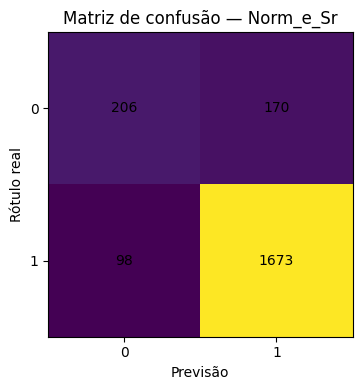

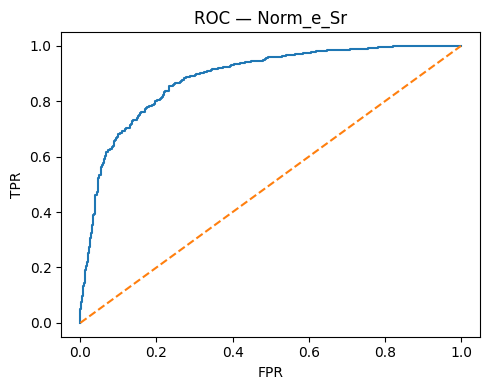

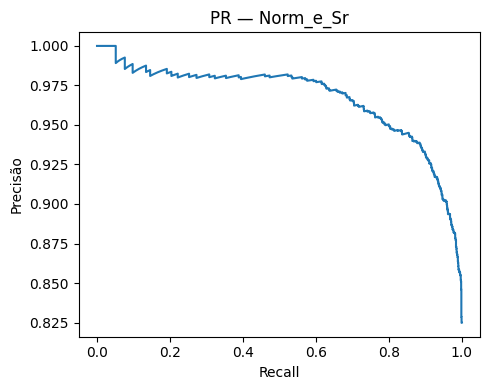

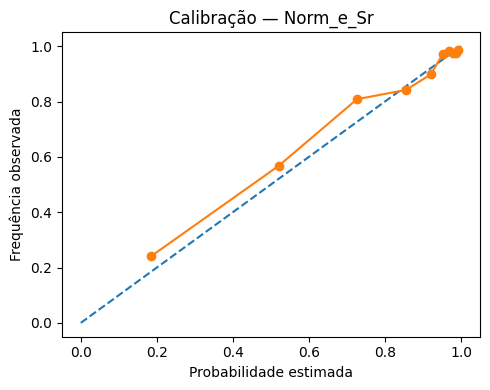

MODELO SALVO: C:\Users\Matheus\Documents\PTB-XL\modelos_normais\Norm_e_Sr.joblib | F1: 0.9258 | AUC: 0.8841


,n,positivos,negativos,accuracy,balanced_accuracy,precision,recall,specificity,f1,tn,...,f1_ic95_sup,roc_auc_ic95_inf,roc_auc_ic95_sup,modelo,C,n_treino_efetivo,n_calibracao,n_teste,limiar,validacao_C_balanced_accuracy
0,2147,1771,376,0.875175,0.746268,0.907759,0.944664,0.547872,0.925844,206,...,0.933391,0.865835,0.900305,Norm_e_Sr,3.0,5000,2142,2147,0.5,0.819578


Arquivo exportado: C:\Users\Matheus\Documents\PTB-XL\modelos_normais\Norm_e_Sr.joblib


In [8]:
X=merged[FEATURE_COLS].to_numpy(dtype=float)
fold=merged.strat_fold.to_numpy(dtype=int)
ids_train=np.flatnonzero(np.isin(fold,FOLDS_TREINO))
ids_hyper_train=np.flatnonzero(np.isin(fold,range(1,8)))
ids_val_c=np.flatnonzero(fold==8)
ids_cal=np.flatnonzero(fold==FOLD_CALIBRACAO)
ids_test=np.flatnonzero(fold==FOLD_TESTE)

label='Norm_e_Sr'
print('Treinando um único modelo:',label,flush=True)
y=merged[label].to_numpy(dtype=int)
for part,nome in [(ids_hyper_train,'ajuste C - treino'),(ids_val_c,'ajuste C - validação'),(ids_train,'treino final'),(ids_cal,'calibração'),(ids_test,'teste')]:
    if len(np.unique(y[part]))<2:raise RuntimeError(f'{nome} sem ambas as classes')
best_C=None;best_score=-1
train_h=sample_train(y,ids_hyper_train,MAX_TREINO_POR_CLASSE)
for C in C_CANDIDATOS:
    candidate=pipeline_svm(C)
    candidate.fit(X[train_h],y[train_h])
    score=float(balanced_accuracy_score(y[ids_val_c],candidate.predict(X[ids_val_c])))
    print('C:',C,'| balanced accuracy fold 8:',round(score,4))
    if score>best_score:best_score=score;best_C=C
    del candidate
ids_fit=sample_train(y,ids_train,MAX_TREINO_POR_CLASSE)
model=pipeline_svm(best_C)
model.fit(X[ids_fit],y[ids_fit])
scores_cal=model.decision_function(X[ids_cal])
calibrator=platt_fit(scores_cal,y[ids_cal])
scores_test=model.decision_function(X[ids_test])
prob_test=probabilities(calibrator,scores_test)
threshold=0.5
met,pred=metrics_binary(y[ids_test],prob_test,threshold)
met.update(bootstrap_ci(y[ids_test],prob_test,threshold))
met.update({'modelo':label,'C':best_C,'n_treino_efetivo':len(ids_fit),'n_calibracao':len(ids_cal),
            'n_teste':len(ids_test),'limiar':threshold,'validacao_C_balanced_accuracy':best_score})
artifact={
    'model':model,'calibrator':calibrator,'features':list(FEATURE_COLS),
    'label':label,'task':'normais','categoria':'NORM_OU_SR',
    'tipo':'uniao_codigos_scp',
    'codigos_scp':['NORM','SR'],
    'threshold':float(threshold),'C':best_C,'calibration':'platt_fold_9',
    'probability_output':True,'probability_method':'calibrator.predict_proba',
    'sex_encoding':{'masculino':0,'feminino':1},
    'age_groups':{'pediatrico':[0,16],'adulto_jovem':[17,39],'adulto':[40,59],'idoso':[60,None]},
    'train_folds':FOLDS_TREINO,'hyperparameter_validation_fold':8,'validation_fold':9,'test_fold':10,
    'class_positive':1,'definicao_alvo':'NORM in scp_codes OR SR in scp_codes','training_samples':len(ids_fit),
    'note':'Probabilidade calibrada exploratória do rótulo NORM ou SR; SR isolado não prova ECG normal.'
}
file=DESTINO/'Norm_e_Sr.joblib'
joblib.dump(artifact,file,compress=3)
check=joblib.load(file)
assert check['label']==label and len(check['features'])==128
pred_df=pd.DataFrame({'ecg_id':merged.iloc[ids_test].ecg_id.to_numpy(),
  'patient_id':merged.iloc[ids_test].patient_id.to_numpy(),
  'idade':merged.iloc[ids_test].age.to_numpy(),'sexo':merged.iloc[ids_test].sex_ptbxl.to_numpy(),
  'y_true':y[ids_test],'y_pred':pred,'escore_svm':scores_test,
  'probabilidade_calibrada':prob_test,'percentual':100*prob_test,'limiar':threshold})
pred_df.to_csv(DESTINO/'previsoes'/f'{label}_previsoes.csv',index=False,encoding='utf-8-sig')
report=pd.DataFrame([met])
INVENTARIO=[{'label':label,'arquivo':file.name,'features':len(FEATURE_COLS),'n_teste':len(ids_test)}]
pd.DataFrame([met]).to_csv(DESTINO/'relatorios'/f'{label}_metricas.csv',index=False,encoding='utf-8-sig')
plot_eval(label,y[ids_test],prob_test,pred,threshold)
print('MODELO SALVO:',file,'| F1:',round(met['f1'],4),'| AUC:',round(met['roc_auc'],4))
# Relatórios e inventário só são escritos se o treinamento concluiu.
report.to_csv(DESTINO/'relatorios'/'resumo_treinamento.csv',index=False,encoding='utf-8-sig')
pd.DataFrame(columns=['alvo','erro']).to_csv(DESTINO/'relatorios'/'erros_treinamento.csv',index=False,encoding='utf-8-sig')
(DESTINO/'inventario_modelos.json').write_text(json.dumps({
  'modelos':INVENTARIO,'metodologia':'SVM RBF e Platt','semente':SEED,
  'definicao_alvo':'NORM ou SR: união sem duplicar registros',
  'folds':{'treino':FOLDS_TREINO,'selecionar_C':8,'calibracao':9,'teste':10},
  'observacao':'Um único modelo binário Norm_e_Sr.joblib.'},
  indent=2,ensure_ascii=False),encoding='utf-8')
display(report)
print('Arquivo exportado:',str(file))


## 9. Distribuição por idade e sexo — alvo unificado

A tabela mostra a porcentagem de registros rotulados como `NORM` ou `SR` **dentro de cada faixa etária e sexo**, usando somente os ECGs elegíveis com características extraídas. Não é a probabilidade de doença ou saúde.

In [9]:
long=merged[['ecg_id','strat_fold','age','sex_ptbxl','Norm_e_Sr']].copy()
long['faixa_etaria']=long.age.map(age_group)
long['sexo']=long.sex_ptbxl.map({0:'masculino',1:'feminino'}).fillna('desconhecido')
rows=[]
for (faixa,sexo),part in long.groupby(['faixa_etaria','sexo'],dropna=False):
    rows.append({'alvo':'Norm_e_Sr','faixa':faixa,'sexo':sexo,'n':len(part),
                 'positivos':int(part['Norm_e_Sr'].sum()),
                 'prevalencia_percentual':100*part['Norm_e_Sr'].mean()})
subgrupos=pd.DataFrame(rows)
display(subgrupos)
subgrupos.to_csv(DESTINO/'relatorios'/'distribuicao_idade_sexo.csv',index=False,encoding='utf-8-sig')

,alvo,faixa,sexo,n,positivos,prevalencia_percentual
0,Norm_e_Sr,adulto_40_59,feminino,2905,2678,92.185886
1,Norm_e_Sr,adulto_40_59,masculino,3842,3328,86.621551
2,Norm_e_Sr,adulto_jovem_17_39,feminino,1362,1308,96.035242
3,Norm_e_Sr,adulto_jovem_17_39,masculino,1293,1194,92.343387
4,Norm_e_Sr,desconhecido,feminino,225,132,58.666667
5,Norm_e_Sr,desconhecido,masculino,67,36,53.731343
6,Norm_e_Sr,idoso_60_mais,feminino,5728,4469,78.020251
7,Norm_e_Sr,idoso_60_mais,masculino,5846,4387,75.042764
8,Norm_e_Sr,pediatrico_0_16,feminino,47,46,97.872340
9,Norm_e_Sr,pediatrico_0_16,masculino,39,35,89.743590


## 10. Integração ao Visualizador ECG V0.5

O modelo exportado fica **somente** em `modelos_normais/Norm_e_Sr.joblib`. Seus metadados incluem a lista ordenada de 128 características, o pipeline SVM, o calibrador e o limiar. **O visualizador precisa ser atualizado para carregar o novo caminho e executar a mesma extração de características do treino**; apenas copiar o `.joblib` não é suficiente.

A pontuação percentual expressa a estimativa calibrada de correspondência ao rótulo **NORM ou SR**, não a chance de o paciente estar saudável.

In [10]:
def predict_normais(artifact_path, frame):
    """Uma ou mais linhas com características de treino, já extraídas corretamente."""
    a=joblib.load(artifact_path)  # somente artefatos próprios e confiáveis
    missing=[c for c in a['features'] if c not in frame.columns]
    if missing:raise ValueError('Features faltantes: '+', '.join(missing[:10]))
    Xnovo=frame[a['features']].to_numpy(dtype=float)
    scores=a['model'].decision_function(Xnovo)
    prob=probabilities(a['calibrator'],scores)
    return pd.DataFrame({'modelo':a['label'],'escore':scores,
                         'probabilidade_calibrada':prob,'percentual_exploratorio':prob*100,
                         'classe_positiva':prob>=a['threshold']})

# Exemplo real após treinamento e processamento de sinais:
# amostra=merged.loc[merged.strat_fold==10].head(3)
# display(predict_normais(DESTINO/'Norm_e_Sr.joblib',amostra))

## 11. Limitações e conclusões

- Treina-se **somente um modelo** `Norm_e_Sr.joblib` para a **união** de `NORM` e `SR` (um ECG com os dois códigos conta uma vez).
- `SR` é ritmo sinusal e não implica, isoladamente, ECG normal. Chamar a união de *ausência de alterações* seria incorreto.
- Registros com `NORM` e códigos diagnósticos anormais são excluídos pelo filtro de referência e contabilizados.
- O CSV contém metadados/rótulos, **não** os sinais. O treinamento depende dos arquivos WFDB `.dat`/`.hea` da PTB-XL.
- O notebook prepara e exporta o modelo quando executado, **não** inclui um modelo fictício pré-treinado.
- A inferência em produção só deve ser integrada após verificar a correspondência exata das 128 características e versões de dependências.
- Calibração probabilística do rótulo não equivale a validação clínica independente.